# SPF EX1 - Alan Jesús Hernández Soto

1.- Se crea un contrato de compra donde se quiere que la acción sea estable. La persona con la que estás haciendo el contrato accede a comprar el 50% de las acciones de tu empresa si la volatilidad móvil con n=20 (anualizada) no excede el 20%. El archivo ex1_01 contiene dos rutas. ¿En cuál de las dos situaciones se activa el contrato?

In [160]:
import pandas as pd
import numpy as np

df = pd.read_excel('ex1_01.xlsx', index_col='Día')
vol_movil_a = []
vol_movil_b = []

df = df.pct_change().dropna()

ruta_a = np.array(df['Ruta A'].values)
ruta_b = np.array(df['Ruta B'].values)


for i in range(len(df)-19):
    vol_movil_a.append(ruta_a[i:20+i].std())
    vol_movil_b.append(ruta_b[i:20+i].std())

vol_movil_a = np.array(vol_movil_a)
vol_movil_b = np.array(vol_movil_b)

print(vol_movil_a.mean()*np.sqrt(252))
print(vol_movil_b.mean()*np.sqrt(252))


0.16583082641129387
0.29623740969128676


Se activa en la Ruta B ya que su volatilidad movil es de 16.58% anual mientras que de la ruta a es de 29.62% anual.

2.- Utilizando S0=100, r=0.05, sigma=0.20, T=1, n=252, y un GBM, considera los siguientes supuestos:

A partir del día 30 sabes que el banco central aumentará las tasas de interés al 8%
Sabes que a partir del día 50, después de una junta de accionistas, la volatilidad aumentará a 40% por 20 días; luego de eso, regresará a la normalidad.
Históricamente, las veces que se ha hecho un anuncio importante sobre el portafolio de la empresa para nuevos productos de venta, se producen reacciones fuertemente positivas e inmediatas en el precio de la acción durante 1 semana; se regresa a la normalidad después de esa semana. La presentación está calendarizada para el día 120.

In [161]:
paths = np.zeros((10000, 253))
np.random.seed(123)

paths[:, 0] = 100
# Dia 1-30
for i in range(1, 31):
    paths[:, i] = paths[:, i-1]*np.exp(((0.05-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(0,1,10000)))

# Dia 31-50
for i in range(31, 51):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(0,1,10000)))

# Dia 51-70
for i in range(51, 71):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.4**2))*(1/252)) + (0.4*np.sqrt(1/252)*np.random.normal(0,1,10000)))

# Dia 71-120
for i in range(71, 121):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(0,1,10000)))

# Dia 121-127
for i in range(121, 128):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(1,1,10000)))

# Dia 128-252
for i in range(128, 253):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(0,1,10000)))



Se simula dia por dia, dividiendolos manualmente los dias para la simulacion de cada cambio.

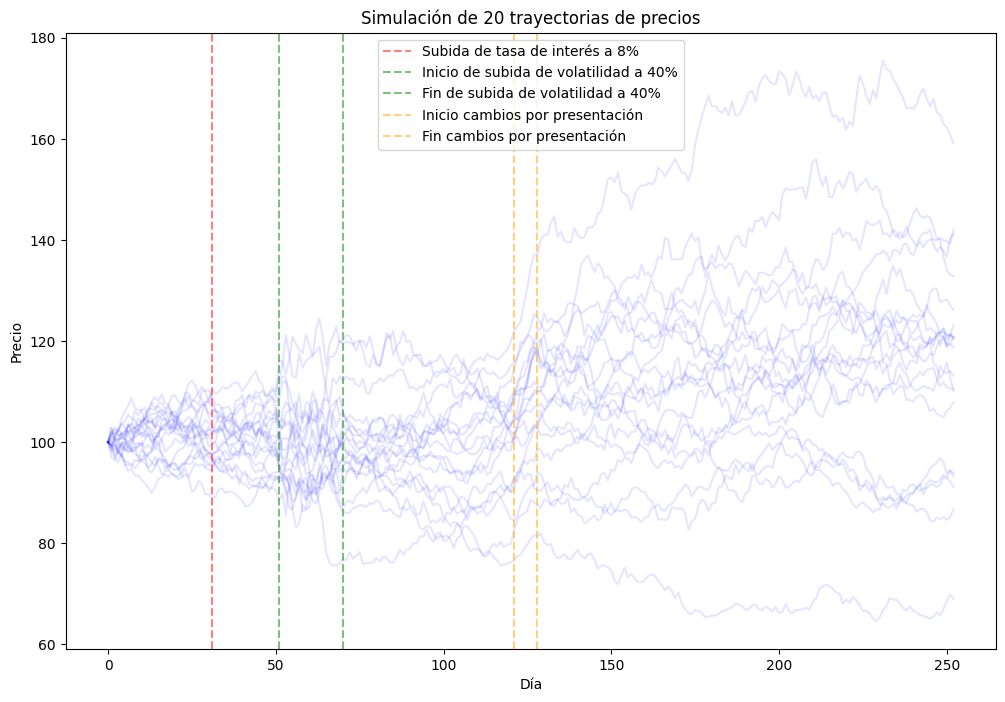

In [163]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
for i in range(20):
    plt.plot(paths[i, :], color='blue', alpha=0.1)
plt.title('Simulación de 20 trayectorias de precios')
plt.xlabel('Día')
plt.ylabel('Precio')
plt.axvline(31, color='red', linestyle='--', label='Subida de tasa de interés a 8%', alpha=0.5)
plt.axvline(51, color='green', linestyle='--', label='Inicio de subida de volatilidad a 40%', alpha=0.5)
plt.axvline(70, color='green', linestyle='--', label='Fin de subida de volatilidad a 40%', alpha=0.5)
plt.axvline(121, color='orange', linestyle='--', label='Inicio cambios por presentación', alpha=0.5)
plt.axvline(128, color='orange', linestyle='--', label='Fin cambios por presentación', alpha=0.5)
plt.legend()
plt.show()